# Jacobiano y singularidades: la cinemática de movimiento

**Taller de Proyecto I (E0306) — 2.º cuatrimestre 2026 — Grupo N.º 3**

---

## Alcance

El cuaderno de cinemática directa contesta **dónde queda el vaso** para cada juego de ángulos.
Este contesta la pregunta que sigue, y que es la que el mando necesita: **cómo se mueve el
vaso cuando se mueven las articulaciones**. Es lo que la bibliografía llama cinemática de
movimiento o cinemática diferencial, y el objeto que la resuelve es el **jacobiano**.

Resuelve cuatro cosas:

1. Una **verificación con herramienta de terceros** de la tabla de Denavit-Hartenberg, con el
   *Robotics Toolbox* de Peter Corke. Hasta acá todo se verificó contra cálculos propios, que
   comparten el modo de razonar: si el error fuera de concepto, no se vería.
2. El **jacobiano** del brazo, a mano y con el toolbox.
3. Las **singularidades**: dónde el brazo pierde capacidad de mover la punta, y qué tan cerca
   está la ventana de recorrido adoptada de ese lugar.
4. La **transpuesta del jacobiano**, que mapea una fuerza en la punta a pares en las
   articulaciones, y que sirve de control cruzado del dimensionamiento estático.

> El toolbox se instala con `pip install roboticstoolbox-python`. Si no está instalado, la
> sección 1 lo avisa y el resto del cuaderno corre igual: solo usa `math`, `numpy` y
> `matplotlib`.

In [1]:
import math
import numpy as np

L1, L2, L3 = 120.0, 120.0, 85.0          # mm
H_HOMBRO = 190.0                         # altura del hombro sobre la mesa
Z_GARRA = 70.0                           # altura de la punta al agarrar
VENT_H, VENT_C, VENT_M = (50.0, 110.0), (0.0, 120.0), (-108.0, 40.0)
CAJA_H, R_GUARDA = 100.0, 113.0          # la caja base, y el radio de la guarda
M_VASO, G = 0.145, 9.81                  # kg y m/s2

def directa(q1, q2, q3, q4):
    '''La formula del cuaderno de cinematica directa, en radianes.'''
    a2, a23, a234 = q2, q2 + q3, q2 + q3 + q4
    r = L1*math.sin(a2) + L2*math.sin(a23) + L3*math.sin(a234)
    z = H_HOMBRO + L1*math.cos(a2) + L2*math.cos(a23) + L3*math.cos(a234)
    return r*math.cos(q1), r*math.sin(q1), z

def articulaciones(q2, q3, q4):
    '''(r, z) de hombro, codo, muneca y punta. En radianes.'''
    a23, a234 = q2 + q3, q2 + q3 + q4
    co = (L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2))
    mu = (co[0] + L2*math.sin(a23), co[1] + L2*math.cos(a23))
    return [(0.0, H_HOMBRO), co, mu, (mu[0] + L3*math.sin(a234),
                                      mu[1] + L3*math.cos(a234))]

def libre(q2, q3, q4):
    '''La guarda del cuaderno anterior: nada bajo la tapa dentro del radio de esquina.'''
    return all(z >= 0 and not (z < CAJA_H and abs(r) < R_GUARDA)
               for r, z in articulaciones(q2, q3, q4))

def inversa(r, z):
    '''Angulos en grados para una punta en (r, z) con la pinza horizontal.'''
    rx, zy = r - L3, z - H_HOMBRO
    d = math.hypot(rx, zy)
    if d > L1 + L2:
        return None
    semi = math.acos(min(1.0, d/(L1 + L2)))        # L1 = L2: triangulo isosceles
    medio = math.atan2(rx, zy)
    for s in (1, -1):                              # codo abajo y codo arriba
        q2, q3 = medio - s*semi, 2*s*semi
        g = [math.degrees(q2), math.degrees(q3)]
        g.append(90 - g[0] - g[1])
        if (VENT_H[0] <= g[0] <= VENT_H[1] and VENT_C[0] <= g[1] <= VENT_C[1]
                and VENT_M[0] <= g[2] <= VENT_M[1]
                and libre(q2, q3, math.radians(g[2]))):
            return g
    return None

---

# 1. Verificación con el Robotics Toolbox

La tabla se carga tal cual está documentada, con el corrimiento de −90° del hombro declarado
como `offset` en vez de restarlo a mano, y se compara contra la fórmula geométrica del
firmware en 20 000 configuraciones al azar.

Esto es lo que las verificaciones anteriores no podían dar: el toolbox implementa el método de
Denavit-Hartenberg con su propio código, su propia convención de ejes y su propia álgebra, y
no comparte nada con nuestros cálculos salvo los cuatro números por fila.

In [2]:
try:
    import roboticstoolbox as rtb
    brazo = rtb.DHRobot([
        rtb.RevoluteDH(d=H_HOMBRO, a=0.0, alpha=-math.pi/2),     # base
        rtb.RevoluteDH(d=0.0, a=L1, alpha=0.0, offset=-math.pi/2),  # hombro
        rtb.RevoluteDH(d=0.0, a=L2, alpha=0.0),                  # codo
        rtb.RevoluteDH(d=0.0, a=L3, alpha=0.0)],                 # muneca
        name="Brazo Grupo 3")
    print(brazo)

    rng = np.random.default_rng(3)
    peor = 0.0
    for q in rng.uniform(-math.pi, math.pi, size=(20000, 4)):
        peor = max(peor, float(np.max(np.abs(
            np.array(brazo.fkine(q).t) - np.array(directa(*q))))))
    print(f"20 000 configuraciones al azar, toolbox contra la formula del firmware")
    print(f"  discrepancia maxima: {peor:.1e} mm")
except ImportError:
    brazo = None
    print("Robotics Toolbox no instalado: esta seccion NO verifica nada.")
    print("  instalarlo con: pip install roboticstoolbox-python")

DHRobot: Brazo Grupo 3, 4 joints (RRRR), standard DH parameters
┌───────────┬─────┬─────┬────────┐
│    θⱼ     │ dⱼ  │ aⱼ  │   ⍺ⱼ   │
├───────────┼─────┼─────┼────────┤
│  q1       │ 190 │   0 │ -90.0° │
│  q2 - 90° │   0 │ 120 │   0.0° │
│  q3       │   0 │ 120 │   0.0° │
│  q4       │   0 │  85 │   0.0° │
└───────────┴─────┴─────┴────────┘



20 000 configuraciones al azar, toolbox contra la formula del firmware
  discrepancia maxima: 1.8e-13 mm


La tabla que imprime el toolbox es, columna por columna, la que está documentada. Y la
discrepancia es ruido de punto flotante, así que **la tabla y la fórmula del firmware quedan
verificadas contra una implementación independiente**, publicada y de uso académico corriente.

---

# 2. El jacobiano

El jacobiano es la matriz que relaciona **velocidad de articulación** con **velocidad de la
punta**:

$$\dot{x} = J(q)\,\dot{q}$$

Depende de la configuración, no es constante: el mismo giro del codo mueve la punta distinto
según dónde esté el brazo.

Para el brazo completo `J` es de 6×4 —tres filas de velocidad lineal y tres de velocidad
angular, una columna por articulación— y no es cuadrada, porque cuatro articulaciones no
alcanzan para imponer las seis componentes de velocidad de un cuerpo en el espacio. Pero en
**modo de traslado** el problema se reduce, y mucho.

### En modo de traslado el brazo es un 2R plano

Durante el traslado la muñeca mantiene la pinza horizontal, `α234 = 90°`
(muñeca asistida, ADR-004). Con esa condición el último eslabón aporta una constante al radio
y nada a la altura, así que la punta se mueve **exactamente** como la muñeca, y el problema
queda en dos articulaciones y dos coordenadas:

$$J = \begin{pmatrix}
L_1\cos q_2 + L_2\cos(q_2{+}q_3) & L_2\cos(q_2{+}q_3) \\
-L_1\,\mathrm{sen}\,q_2 - L_2\,\mathrm{sen}(q_2{+}q_3) & -L_2\,\mathrm{sen}(q_2{+}q_3)
\end{pmatrix}$$

con las filas `(ṙ, ż)` y las columnas `(q̇2, q̇3)`. Los ángulos se miden desde la vertical, de
ahí que aparezcan cambiados los senos y cosenos respecto de la forma que trae la
bibliografía, que los mide desde la horizontal.

In [3]:
def jacobiano(q2, q3):
    '''2x2: filas (r_punto, z_punto), columnas (q2_punto, q3_punto). En radianes.'''
    a23 = q2 + q3
    return np.array([
        [ L1*math.cos(q2) + L2*math.cos(a23),  L2*math.cos(a23)],
        [-L1*math.sin(q2) - L2*math.sin(a23), -L2*math.sin(a23)]])

# control: contra diferencias finitas de la propia formula directa
def punta_rz(q2, q3):
    q4 = math.pi/2 - q2 - q3                      # muneca asistida
    x, y, z = directa(0.0, q2, q3, q4)
    return np.array([x, z])

h, peor = 1e-6, 0.0
for a2 in (50, 70, 90, 110):
    for a3 in (5, 40, 80, 120):
        q2, q3 = math.radians(a2), math.radians(a3)
        num = np.column_stack([
            (punta_rz(q2 + h, q3) - punta_rz(q2 - h, q3))/(2*h),
            (punta_rz(q2, q3 + h) - punta_rz(q2, q3 - h))/(2*h)])
        peor = max(peor, float(np.max(np.abs(num - jacobiano(q2, q3)))))
print(f"jacobiano analitico contra diferencias finitas: {peor:.1e} mm/rad")

if brazo is not None:      # y contra el toolbox, en la pose de agarre
    g = inversa(250.0, Z_GARRA)
    q = np.radians([0.0] + g)
    J6 = brazo.jacob0(q)
    np.set_printoptions(precision=1, suppress=True)
    print("\njacob0 del toolbox en la pose de agarre a r = 250, z = 70 (6x4):")
    print(J6)

    # El toolbox evalua los cuatro ejes LIBRES. Con la muneca asistida,
    # q4 = 90 - q2 - q3, asi que dq4/dq2 = dq4/dq3 = -1 y por regla de la cadena
    # las columnas utiles son la del eje menos la de la muneca.
    asis = np.column_stack([J6[:, 1] - J6[:, 3], J6[:, 2] - J6[:, 3]])
    Ja = jacobiano(q[1], q[2])
    print("\ncon la muneca asistida, por regla de la cadena (filas r y z):")
    print(f"  toolbox  : {asis[0, 0]:8.1f} {asis[0, 1]:8.1f} / "
          f"{asis[2, 0]:8.1f} {asis[2, 1]:8.1f}")
    print(f"  analitico: {Ja[0, 0]:8.1f} {Ja[0, 1]:8.1f} / "
          f"{Ja[1, 0]:8.1f} {Ja[1, 1]:8.1f}")
    print(f"  diferencia maxima: "
          f"{max(abs(asis[0, 0] - Ja[0, 0]), abs(asis[0, 1] - Ja[0, 1]), abs(asis[2, 0] - Ja[1, 0]), abs(asis[2, 1] - Ja[1, 1])):.1e} mm/rad")

jacobiano analitico contra diferencias finitas: 4.5e-08 mm/rad

jacob0 del toolbox en la pose de agarre a r = 250, z = 70 (6x4):
[[  -0.  -120.  -111.1   -0. ]
 [ 250.     0.     0.     0. ]
 [   0.  -250.  -130.3  -85. ]
 [  -0.     0.     0.     0. ]
 [   0.     1.     1.     1. ]
 [   1.     0.     0.     0. ]]

con la muneca asistida, por regla de la cadena (filas r y z):
  toolbox  :   -120.0   -111.1 /   -165.0    -45.3
  analitico:   -120.0   -111.1 /   -165.0    -45.3
  diferencia maxima: 2.8e-14 mm/rad


Las dos cosas que se comparan ahí merecen una aclaración, porque es fácil leerlas como una
contradicción. El toolbox evalúa el brazo con **los cuatro ejes libres**, y entonces mover el
hombro arrastra también al último eslabón: su columna de altura vale −250 mm/rad. El 2R plano
vale **bajo la condición de pinza horizontal**, donde la muñeca no es libre sino que compensa, y
da −165.

La diferencia son exactamente los 85 mm del último eslabón, y se pasa de una a otra por regla de
la cadena: como `q4 = 90° − q2 − q3`, resulta `∂q4/∂q2 = ∂q4/∂q3 = −1`, así que la columna útil
es **la del eje menos la de la muñeca**. Hecha esa cuenta, el toolbox y el jacobiano analítico
coinciden hasta el último decimal. Son dos modelos del mismo brazo: el que manda en traslado es
el de la muñeca asistida, porque es el que implementa el firmware.

---

# 3. Singularidades: dónde el brazo se queda sin dirección

El determinante del jacobiano sale limpio:

$$\det J = L_1 L_2\,\mathrm{sen}\,q_3 = 14\,400\;\mathrm{sen}\,q_3\;[\mathrm{mm}^2]$$

y **no depende del hombro**: solo del codo. Se anula en `q3 = 0°` —el codo estirado— y en
`q3 = 180°` —el codo plegado sobre sí mismo, que el brazo no alcanza—.

Que el determinante se anule significa que las dos columnas se vuelven paralelas: las dos
articulaciones empujan la punta en la misma dirección y **se pierde una dirección de
movimiento**. Con el codo estirado, el brazo puede subir y bajar la punta pero no puede
acercarla ni alejarla: para moverse en radio tendría que plegar el codo, y justo ahí el codo no
produce movimiento radial.

Y acá aparece algo que hay que mirar de frente: **`q3 = 0` es exactamente el borde de la
ventana de recorrido adoptada** (0° a 120°, ADR-010). La pregunta no es si la singularidad está
en el rango —está, en el extremo— sino **si el brazo trabaja cerca de ella**.

In [4]:
print(f"{'q3':>7}{'det J [mm2]':>14}{'cond(J)':>10}   que significa")
print('-' * 72)
for a3 in (0.0, 1.0, 5.0, 21.4, 45.0, 63.6, 92.8, 120.0):
    J = jacobiano(math.radians(90.0), math.radians(a3))
    det = abs(np.linalg.det(J))              # el signo es solo el orden de las filas
    cond = np.linalg.cond(J)
    nota = ('SINGULAR: el codo no mueve la punta en radio' if det < 1e-6 else
            'casi singular' if cond > 50 else
            'extremo exterior de la banda util' if abs(a3 - 21.4) < 0.1 else
            'extremo interior de la banda util' if abs(a3 - 92.8) < 0.1 else '')
    ct = 'infinita' if det < 1e-6 else f"{cond:.2f}"
    print(f"{a3:>7.1f}{det:>14.0f}{ct:>10}   {nota}")

# rango de codo que el brazo usa de verdad, a la altura de agarre
usados = [(r, inversa(float(r), Z_GARRA)) for r in range(150, 320)]
usados = [(r, g) for r, g in usados if g]
q3s = [g[1] for _, g in usados]
dets = [abs(np.linalg.det(jacobiano(math.radians(g[0]), math.radians(g[1]))))
        for _, g in usados]
print(f"\na la altura de agarre, el codo trabaja entre {min(q3s):.1f} y {max(q3s):.1f} grados")
print(f"  radio de {min(r for r, _ in usados)} a {max(r for r, _ in usados)} mm")
print(f"  det J minimo en esa banda: {min(dets):.0f} mm2, "
      f"el {100*min(dets)/14400:.0f} % del maximo posible")
print(f"  la pose singular queda a {min(q3s):.0f} grados de codo de la pose mas estirada")

     q3   det J [mm2]   cond(J)   que significa
------------------------------------------------------------------------
    0.0             0  infinita   SINGULAR: el codo no mueve la punta en radio
    1.0           251    286.47   casi singular
    5.0          1255     57.26   casi singular
   21.4          5254     13.25   extremo exterior de la banda util
   45.0         10182      6.08   
   63.6         12898      4.10   
   92.8         14383      2.51   extremo interior de la banda util
  120.0         12471      1.73   

a la altura de agarre, el codo trabaja entre 21.4 y 92.8 grados
  radio de 199 a 288 mm
  det J minimo en esa banda: 5261 mm2, el 37 % del maximo posible
  la pose singular queda a 21 grados de codo de la pose mas estirada


La lectura es tranquilizadora, y conviene que quede escrita: **la ventana toca la
singularidad en su borde, pero el brazo no trabaja ahí**. A la altura de agarre el codo usa de
21° a 93°, de modo que la pose singular queda a 21° de la pose más estirada que el brazo
realmente adopta, y el determinante nunca baja del 37 % de su máximo.

El número que vale mirar no es el determinante sino el **número de condición**, que dice cuánto
más rígido es el brazo en una dirección que en la otra. En el extremo exterior de la banda vale
13: con la misma velocidad de articulación, la punta se mueve trece veces más rápido hacia
arriba que hacia afuera. No es un problema, pero explica algo que el cuaderno anterior había
medido sin explicar: **por qué el recorrido radial útil se satura** al alejarse. No es que se
acaben los grados, es que ahí los grados casi no mueven el radio.

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

# --- izquierda: det J y condicion contra el angulo del codo ---
a3 = np.linspace(0.0, 120.0, 601)
det = 14400*np.sin(np.radians(a3))
cond = [np.linalg.cond(jacobiano(math.radians(90.0), math.radians(v))) for v in a3]
a1.axvspan(min(q3s), max(q3s), color='tab:green', alpha=.13,
           label=f'codo que el brazo usa a z = 70 ({min(q3s):.0f}° a {max(q3s):.0f}°)')
a1.plot(a3, det/1000, color='tab:blue', lw=2, label='det J')
a1.plot(0, 0, 'o', color='tab:red', ms=9)
a1.annotate('SINGULARIDAD\ncodo estirado\n(borde de la ventana)', xy=(1.2, 0.3),
            xytext=(26, 1.1), fontsize=8.5, color='tab:red',
            arrowprops=dict(arrowstyle='->', color='tab:red', lw=1.1,
                            connectionstyle='arc3,rad=-0.25'))
a1.set_xlabel('q3, angulo del codo [grados]')
a1.set_ylabel('det J [10$^3$ mm$^2$]', color='tab:blue')
a1.set_xlim(-3, 123)
a1.set_ylim(-0.6, 15.5)
a1.grid(alpha=.25)
b1 = a1.twinx()
b1.plot(a3, cond, color='tab:orange', lw=1.4, ls='--', label='cond(J)')
b1.set_ylabel('numero de condicion', color='tab:orange')
b1.set_ylim(0, 40)
a1.set_title('El determinante solo depende del codo', fontsize=10)
h1, l1 = a1.get_legend_handles_labels()
h2, l2 = b1.get_legend_handles_labels()
a1.legend(h1 + h2, l1 + l2, fontsize=7.5, loc='lower right')

# --- derecha: elipses de manipulabilidad sobre el brazo ---
def eslabones(g):
    q2, q3 = math.radians(g[0]), math.radians(g[1])
    co = (L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2))
    mu = (co[0] + L2*math.sin(q2 + q3), co[1] + L2*math.cos(q2 + q3))
    return [(0, H_HOMBRO), co, mu, (mu[0] + L3, mu[1])]

a2.axhline(0, color='0.3', lw=1.4)
a2.add_patch(plt.Rectangle((-82, 0), 164, 100, fc='0.92', ec='0.45'))
a2.add_patch(plt.Rectangle((-22, 100), 44, 90, fc='0.92', ec='0.45'))
for r, color in ((199, 'tab:green'), (250, 'tab:blue'), (288, 'tab:red')):
    g = inversa(float(r), Z_GARRA)
    pts = eslabones(g)
    a2.plot([p[0] for p in pts], [p[1] for p in pts], '-o', color=color, lw=1.6, ms=3.5,
            alpha=.75)
    J = jacobiano(math.radians(g[0]), math.radians(g[1]))
    U, S, _ = np.linalg.svd(J)
    t = np.linspace(0, 2*math.pi, 160)
    e = U @ np.vstack([S[0]*np.cos(t)*0.18, S[1]*np.sin(t)*0.18])
    a2.plot(pts[3][0] + e[0], pts[3][1] + e[1], color=color, lw=1.8,
            label=f'r = {r} mm, codo {g[1]:.0f}°, cond {np.linalg.cond(J):.1f}')
a2.set_xlabel('radio r [mm]')
a2.set_ylabel('altura z [mm]')
a2.set_xlim(-95, 400)
a2.set_ylim(-20, 330)
a2.set_aspect('equal')
a2.grid(alpha=.25)
a2.legend(fontsize=7.5, loc='upper right')
a2.set_title('Elipses de velocidad de la punta (misma velocidad articular)', fontsize=10)

fig.tight_layout()
fig.savefig('fig_jacobiano.png', dpi=150)
print('figura lista')

figura lista


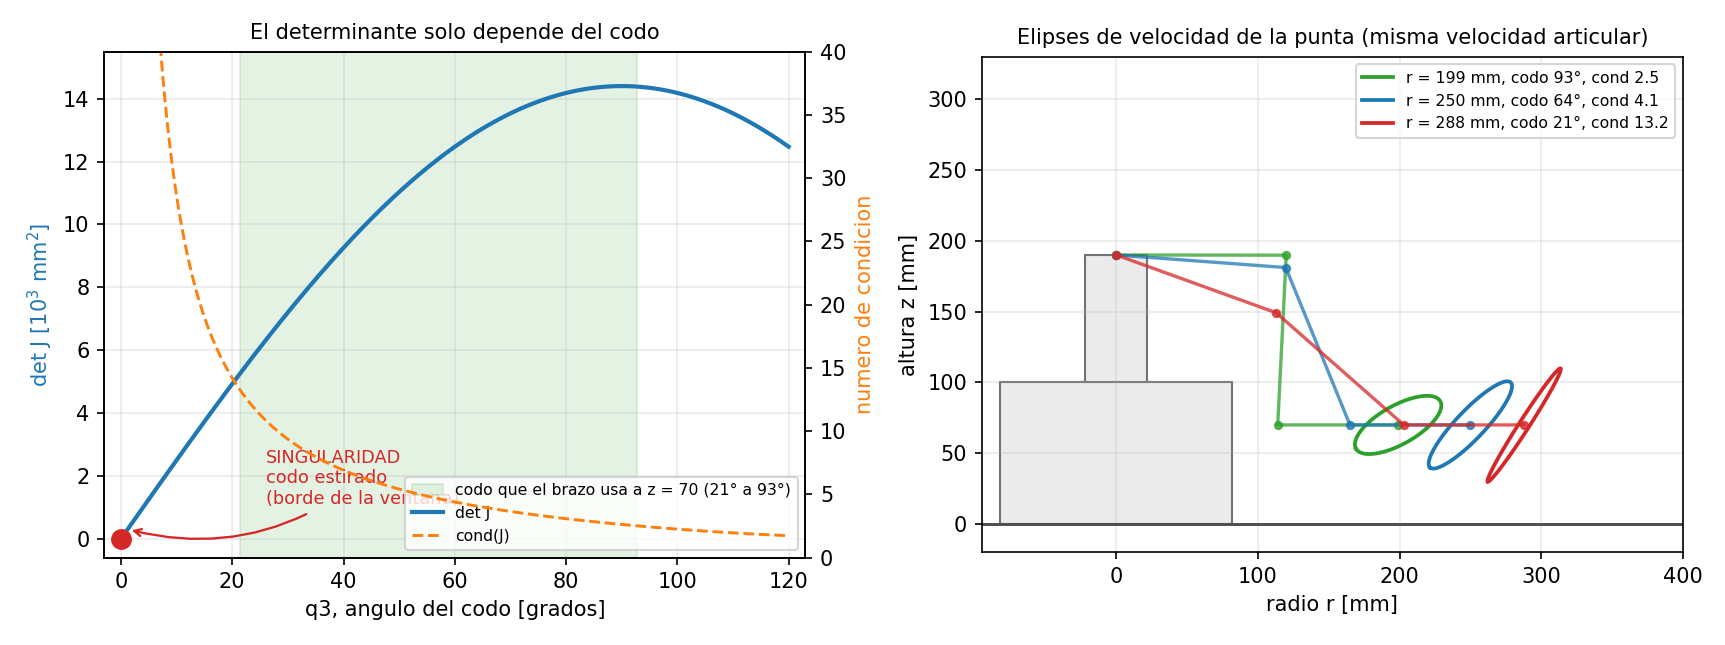

Las elipses son el mismo resultado, dibujado: **con la misma velocidad en las articulaciones,
la punta se mueve distinto según la pose**. Cuanto más estirado el brazo, más achatada la
elipse contra la dirección radial. En el extremo interior de la banda la elipse es casi
redonda; en el exterior es una lonja.

---

# 4. Qué significa esto para el firmware

Acá está la decisión que paga: **el joystick manda velocidad de articulación, no de punta**
([ADR-005](ADR-005-joystick-como-velocidad)). Eso quiere decir que el firmware usa el jacobiano
para *entender* el brazo, pero **nunca tiene que invertirlo**, y la singularidad no puede hacer
explotar nada: no hay división por un determinante que se anula.

Si en cambio se hubiera elegido mandar velocidad cartesiana —«que la punta vaya a 50 mm/s hacia
afuera»— habría que resolver `q̇ = J⁻¹ẋ`, y con el codo estirado eso pide velocidad articular
infinita. El mando por velocidad de articulación no es solo más simple de programar: **esquiva
el problema entero**.

Lo que sí queda como requerimiento práctico:

| Requerimiento | Por qué |
|---|---|
| No programar trayectorias rectas en el espacio con el codo cerca de 0° | ahí la punta no responde en radio; el movimiento sale a tirones |
| Tope del codo en 0°, no en valores negativos | pasado el cero el brazo cruza la singularidad y la solución de codo cambia de rama |
| Para ajuste fino, mover el hombro y no el codo en el extremo exterior | con `cond(J) = 13` el codo casi no mueve el radio ahí |
| Si alguna vez se quiere velocidad cartesiana, usar pseudoinversa con amortiguamiento | es la salida estándar para no dividir por cero cerca de la singularidad |

---

# 5. La transpuesta: de la fuerza en la punta a los pares

El jacobiano tiene una segunda lectura, que cierra el círculo con el dimensionamiento. La
transpuesta mapea una **fuerza aplicada en la punta** a los **pares que aparecen en las
articulaciones**:

$$\tau = J^{T} F$$

El vaso pesa 145 g, así que tira hacia abajo con 1,42 N. Calcular `J^T F` tiene que dar los
mismos pares que el cuaderno de dimensionamiento obtuvo multiplicando peso por brazo de
palanca, y es una verificación cruzada de las dos cosas a la vez.

In [6]:
def pares_por_vaso(g):
    '''Pares [kg.cm] que el peso del vaso produce en hombro, codo y muneca.'''
    q2, q3 = math.radians(g[0]), math.radians(g[1])
    a23 = q2 + q3
    # brazos horizontales de cada eje a la punta, con la pinza horizontal
    pts = [(0.0, H_HOMBRO)]
    pts.append((L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2)))
    pts.append((pts[1][0] + L2*math.sin(a23), pts[1][1] + L2*math.cos(a23)))
    punta = (pts[2][0] + L3, pts[2][1])
    F = M_VASO*G                                   # N, hacia abajo
    return [F*(punta[0] - p[0])/9.81/10 for p in pts]   # N.mm -> kg.cm

print(f"{'pose':<34}{'hombro':>9}{'codo':>8}{'muneca':>9}   [kg.cm]")
print('-' * 70)
for nom, g in (("peor caso: estirado horizontal", [90.0, 0.0, 0.0]),
               ("agarre a r = 250, z = 70", inversa(250.0, Z_GARRA)),
               ("extremo exterior, r = 288", inversa(288.0, Z_GARRA))):
    t = pares_por_vaso(g)
    print(f"{nom:<34}{t[0]:>9.2f}{t[1]:>8.2f}{t[2]:>9.2f}")

if brazo is not None:
    q = np.radians([0.0] + [90.0, 0.0, 0.0])
    W = np.array([0.0, 0.0, -M_VASO*G, 0.0, 0.0, 0.0])
    tau = brazo.jacob0(q).T @ W                    # N.mm
    print("\nlo mismo con J^T del toolbox, en el peor caso [kg.cm]:")
    print(f"  base {tau[0]/98.1:.2f}, hombro {tau[1]/98.1:.2f}, "
          f"codo {tau[2]/98.1:.2f}, muneca {tau[3]/98.1:.2f}")

DOC = {'hombro': 11.96, 'codo': 5.92, 'muneca': 1.62}      # cuaderno de dimensionamiento
t = pares_por_vaso([90.0, 0.0, 0.0])
print("\ncontra los pares documentados en el peor caso:")
for nom, v in zip(('hombro', 'codo', 'muneca'), t):
    print(f"  {nom:<8}{v:6.2f} de {DOC[nom]:6.2f} kg.cm -> el vaso explica el "
          f"{100*v/DOC[nom]:.0f} %; el resto es peso propio del brazo")

pose                                 hombro    codo   muneca   [kg.cm]
----------------------------------------------------------------------
peor caso: estirado horizontal         4.71    2.97     1.23
agarre a r = 250, z = 70               3.62    1.89     1.23
extremo exterior, r = 288              4.18    2.54     1.23

lo mismo con J^T del toolbox, en el peor caso [kg.cm]:
  base 0.00, hombro 4.71, codo 2.97, muneca 1.23

contra los pares documentados en el peor caso:
  hombro    4.71 de  11.96 kg.cm -> el vaso explica el 39 %; el resto es peso propio del brazo
  codo      2.97 de   5.92 kg.cm -> el vaso explica el 50 %; el resto es peso propio del brazo
  muneca    1.23 de   1.62 kg.cm -> el vaso explica el 76 %; el resto es peso propio del brazo


Los tres números coinciden con el cálculo de palanca del dimensionamiento, y el toolbox da lo
mismo por su lado. Lo interesante es el reparto: **el vaso explica menos de la mitad del par
del hombro**; el resto es el brazo cargándose a sí mismo. Por eso aligerar las piezas impresas
mueve el dimensionamiento más que cambiar de recipiente.

Y queda una observación que vale registrar, porque junta las dos mitades del cuaderno: **el
peor caso de par es exactamente la pose singular**. El brazo estirado en horizontal es a la vez
donde más esfuerzo hace el hombro y donde el codo pierde autoridad sobre el radio. Tiene
sentido —es la pose de máxima extensión— pero conviene saber que el peor caso mecánico y el
peor caso cinemático son el mismo punto.

---

# 6. Lo que falta

1. **La cinemática inversa propiamente dicha.** Este cuaderno la usa como herramienta —la
   función `inversa` resuelve el triángulo isósceles— pero no la documenta: falta el análisis de
   las dos ramas, codo arriba y codo abajo, y de qué pasa en el borde del alcance.
2. **Medir el cero de cada eje** al montar, que es lo que convierte todos estos ángulos en
   anchos de pulso.
3. **Verificar la condición en el montaje real**: el número de condición de 13 en el extremo
   exterior se calculó sobre el modelo, y el juego de los engranajes lo va a empeorar.
4. **El jacobiano del brazo completo con los cuatro ejes libres**, si alguna vez se quisiera
   mover la punta en una dirección arbitraria. Para la tarea de este proyecto no hace falta:
   alcanza con el 2R plano más el giro de base.